# Heart Failure Prediction and Patient Segmentation Using Data Mining Techniques

---
# **[1] Problem**

Cardiovascular diseases (CVDs) are the leading cause of death globally, taking an estimated 17.9 million lives each year [1]. Heart failure is a common event caused by CVDs, and early detection is crucial to managing and reducing mortality rates. However, diagnosing heart disease manually based on clinical attributes can be complex due to the interplay of multiple physiological and lifestyle factors.
This project addresses the challenge of early diagnosis by leveraging data mining techniques on clinical measurements (such as resting blood pressure, cholesterol levels, fasting blood sugar, and exercise-induced angina). By uncovering hidden patterns and building predictive models, we aim to assist healthcare professionals in identifying at-risk individuals timely and accurately.

**Motivation:** Early detection of heart failure significantly improves survival rates and treatment outcomes. Utilizing machine learning and data mining enables rapid, automated screening that reduces human diagnostic error and supports clinical decision-making. Working with this curated multi-center dataset provides an impactful opportunity to demonstrate how data science can solve critical, life-saving problems in real-world healthcare settings.

---
# **[2] Data Mining Task**


The primary goal of this project is to apply data mining techniques to the clinical dataset through two main tasks:
* **Classification Task:** To build and evaluate a Decision Tree classification model that predicts whether a patient is at risk of heart disease (HeartDisease = 1) or healthy (HeartDisease = 0) based on their clinical features and test results.
* **Clustering Task:**  To apply K-Means clustering to discover natural sub-groups (clusters) of patients sharing similar health profiles and physiological risk factors, providing insights into distinct patient segments without prior knowledge of their diagnosis.

---
# **[3] Data**

### **Dataset Source**

Kaggle (Heart Failure Prediction Dataset) [2]



Link: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction



### **Dataset Description**

The dataset contains 918 patient records and 12 attributes: 11 clinical features (such as Age, Sex, ChestPainType, RestingBP, Cholesterol, MaxHR and ST_Slope) and the class label **HeartDisease** (1 = heart disease, 0 = normal).


In [1]:
import pandas as pd

df = pd.read_csv('Raw_dataset.csv')



In [2]:
from IPython.display import display, Markdown

display(Markdown("### Dataset Description"))

# Number of objects and attributes
num_records, num_attributes = df.shape
display(Markdown(f"Number of objects (instances/records): {num_records}"))
display(Markdown(f"Number of attributes (features): {num_attributes}"))
print("\n")

# Data types of attributes
display(Markdown("### Data types of attributes"))
print(df.dtypes)
print("\n")

# Class attribute with its values and the count of instances for each label
display(Markdown("### Class attribute count (HeartDisease)"))
class_counts = df['HeartDisease'].value_counts()
print(class_counts)
print("\n")

# Print a sample of the raw dataset
display(Markdown("### Sample of the raw dataset"))
display(df.head())

### Dataset Description

Number of objects (instances/records): 918

Number of attributes (features): 12

### Data types of attributes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object




### Class attribute count (HeartDisease)

HeartDisease
1    508
0    410
Name: count, dtype: int64




### Sample of the raw dataset

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## **Phase 2:** Data Summarization and Preprocessing

## 1. Data Analysis
In this section, we apply different summarization and visualization techniques to better understand our dataset.

### 1.1 Missing Values and Statistical Summaries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('Raw_dataset.csv')

In [4]:
# count missing values in each column
print(df.isna().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


**1. Finding missing values**

It shows that the dataset contains no missing values(null) across all attributes but further inspection shows that there are implicit missing values such as zero values in Cholesterol.







In [5]:
# Exclude binary variables since they are nominal attributes
df.drop(columns=['HeartDisease','FastingBS']).describe()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,136.809368,0.887364
std,9.432617,18.514154,109.384145,25.460334,1.066570
min,28.000000,0.000000,0.000000,60.000000,-2.600000
25%,47.000000,120.000000,173.250000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,138.000000,0.600000
75%,60.000000,140.000000,267.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


**2. Five number summary for numeric attributes**

- **Cholesterol & RestingBP**: Show biologically invalid minimums of 0 (implicit missing values/errors) alongside extreme upper maximums (603 & 200).
- **Age**: Ranges normally between 28 and 77 years (Median: 54).
- **MaxHR**: Spans from 60 to 202 bpm (Median: 138).
- **Oldpeak**: Ranges from -2.6 to 6.2 with potential outliers beyond the whiskers.


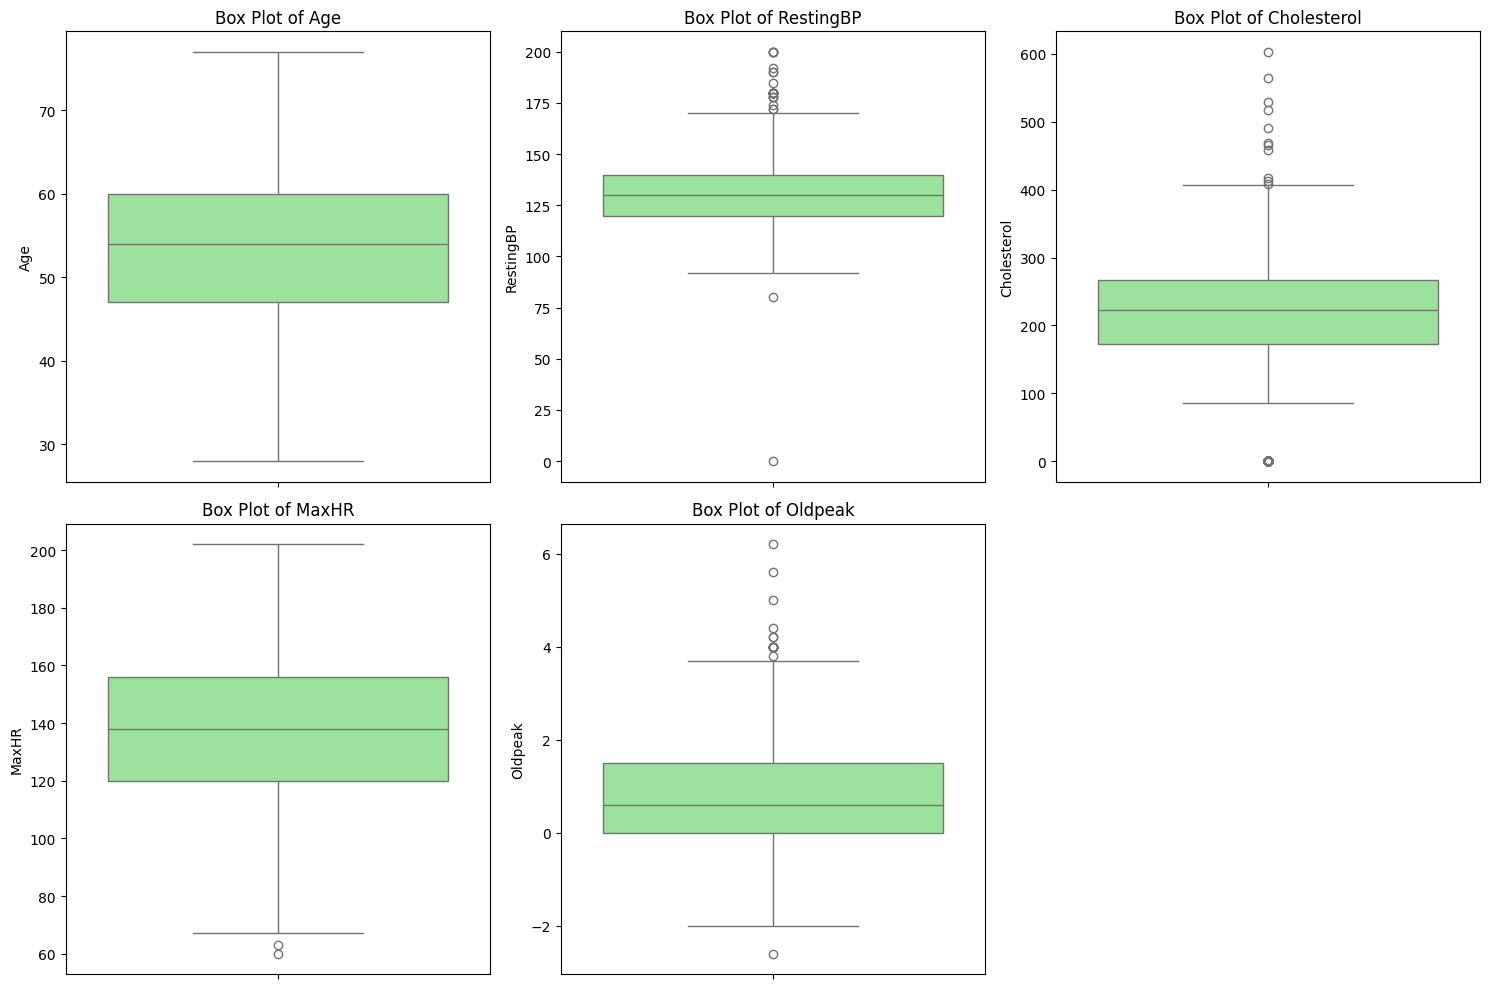

In [6]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Set figure size for a 2x3 grid
plt.figure(figsize=(15, 10))

# Loop through each numeric column to create a box plot
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()



**3. Outlier Analysis & Data Distribution**



The boxplots show the spread, median, and outliers of each numeric attribute. Outliers are the points outside the whiskers (1.5 × IQR from Q1 and Q3).



- **Cholesterol**: Has the largest number of outliers. Many points lie at exactly 0, below the lower whisker, along with several extreme values above roughly 400 mg/dL (up to 603). A cholesterol level of 0 is biologically impossible, so these zeros are implicit missing values rather than real measurements.

- **RestingBP**: The box is narrow (120–140), but there are upper outliers above 170 mmHg (up to 200) and a single impossible value at 0.

- **Oldpeak**: Most values are concentrated between 0 and 1.5, with several upper outliers above 3.75 (up to 6.2) and a few negative values below the lower whisker.

- **MaxHR**: Fairly symmetric, with only a few low outliers around 60 bpm.

- **Age**: Symmetric with no outliers, since all values (28–77) lie within the whiskers.



**Why Preprocessing is needed:** The boxplots confirm that Cholesterol and RestingBP contain invalid zero values that must be replaced, and that RestingBP, Cholesterol, Oldpeak, and MaxHR contain extreme outliers that could distort the analysis. This justifies applying **Noise Removal** (replacing the zeros with the median and capping outliers at the IQR limits).

### 1.2 Data Visualization & Descriptions

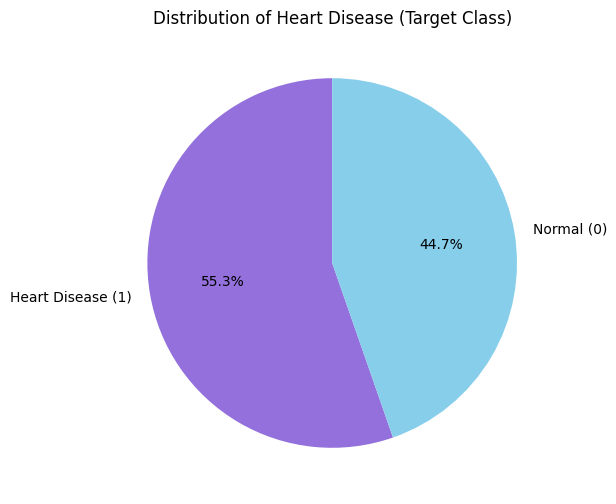

In [7]:
plt.figure(figsize=(6, 6))
heart_disease_freq = df['HeartDisease'].value_counts(normalize=True) * 100
heart_disease_freq.plot.pie(autopct='%1.1f%%', startangle=90, labels=['Heart Disease (1)', 'Normal (0)'], colors=['mediumpurple', 'skyblue'])
plt.title('Distribution of Heart Disease (Target Class)')
plt.ylabel('')
plt.show()

**1. Class Label Distribution (Pie Chart)**
* **Description:** This pie chart illustrates the distribution of the target variable `HeartDisease`. It shows that 55.3% of the patients have heart disease (class 1), while 44.7% are normal (class 0).
* **Why Preprocessing is needed:** The chart shows that our target class is well-balanced (55.3% vs 44.7%), suggesting that class-balancing techniques may not be necessary. Therefore, our preprocessing must focus on cleaning and preparing the input features to help the model accurately predict these two classes.

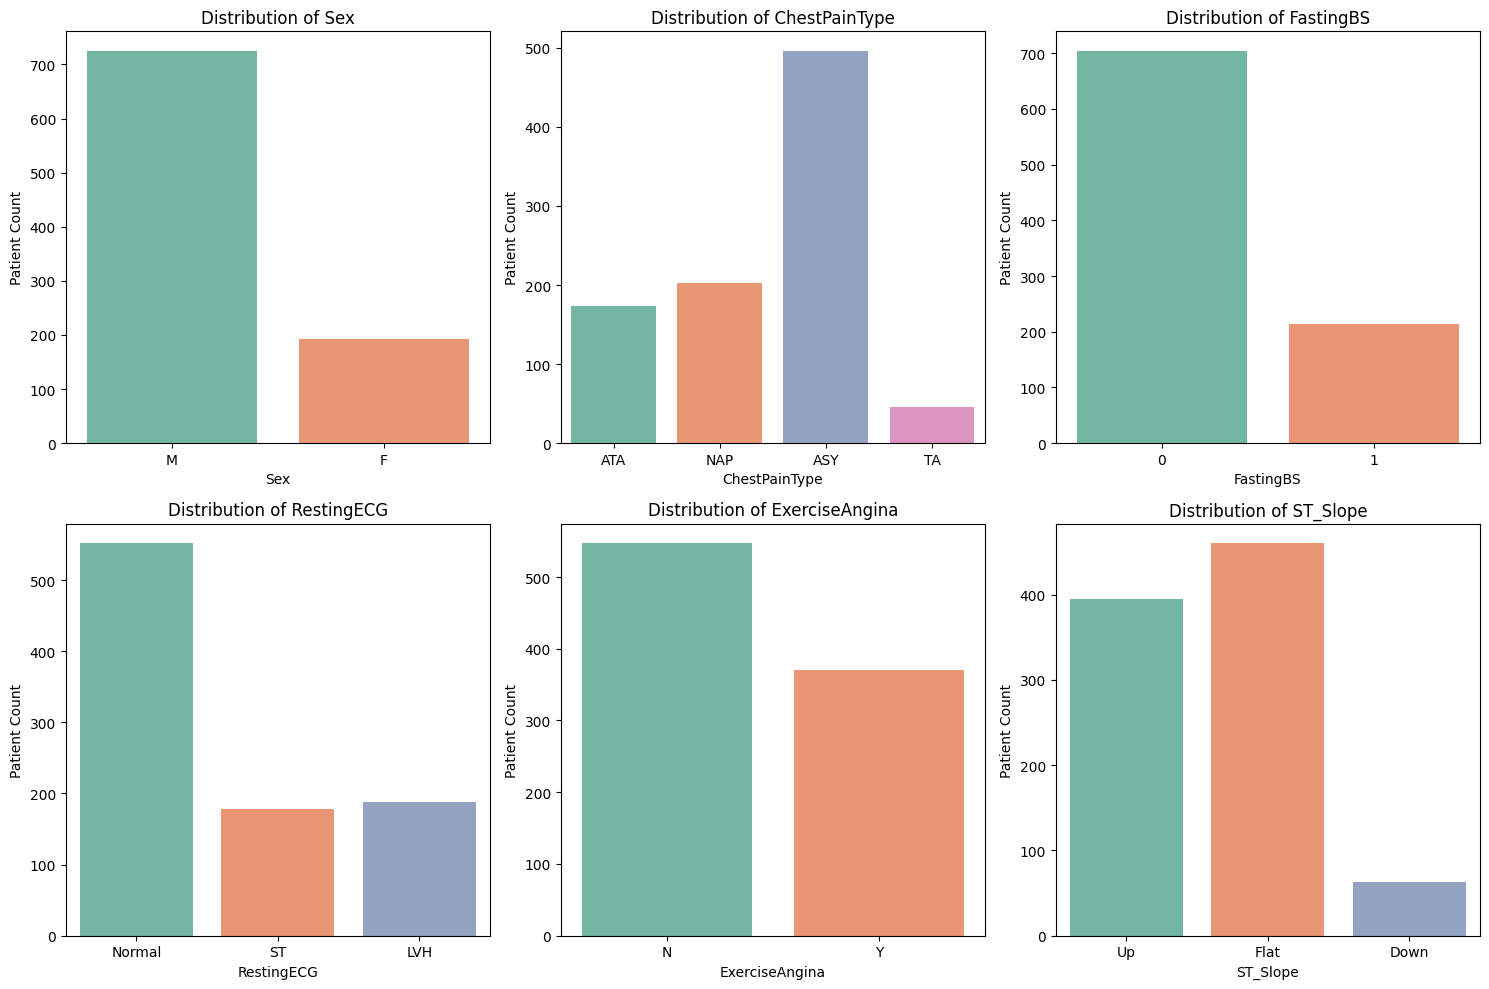

In [8]:
nominal_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG',
                'ExerciseAngina', 'ST_Slope']

# Set figure size for a 2x3 grid (since we have exactly 6 columns)
plt.figure(figsize=(15, 10))

# Loop through each nominal column to create a bar plot
for i, col in enumerate(nominal_cols, 1):
    plt.subplot(2, 3, i)
    sns.countplot(x=df[col], hue=df[col], palette='Set2', legend=False)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Patient Count')

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

**2. Nominal Attributes Distribution (Bar Plot)**
* **Description:** The bar plots visualize the frequency of six categorical attributes: Sex, ChestPainType, FastingBS, RestingECG, ExerciseAngina, and ST_Slope. For ChestPainType, ‘ASY’ (Asymptomatic) is clearly the most common type.
* **Why Preprocessing is needed:** The x-axis shows distinct categorical groups (e.g., ‘ASY’, ‘NAP’, ‘ATA’). These plots help us understand the distribution of categorical attributes and highlight the need for categorical encoding when using machine learning algorithms that require numerical inputs.

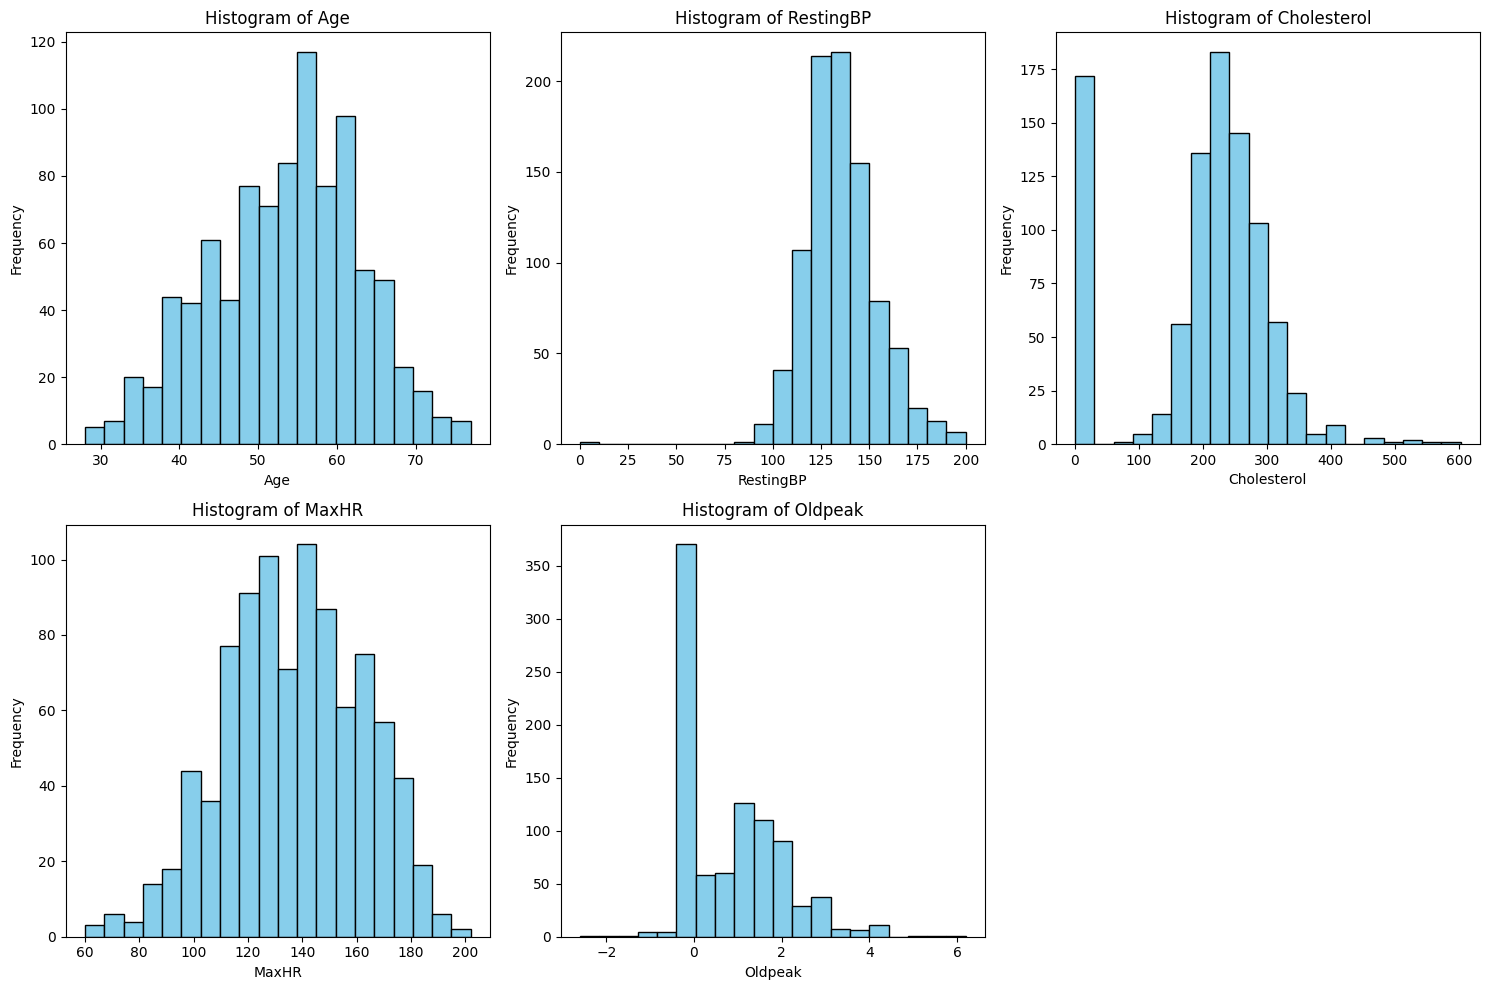

In [9]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Set figure size for a 2x3 grid
plt.figure(figsize=(15, 10))

# Loop through each numeric column to create a histogram
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    df[col].plot.hist(bins=20, color='skyblue', edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

**3. Numeric Attributes Distribution (Histogram)**
* **Description:**  These histograms display the distributions of five numerical attributes: Age, RestingBP, Cholesterol, MaxHR, and Oldpeak. Age is mostly concentrated between 40 and 65, RestingBP around 120–150, and MaxHR around 100–170. Oldpeak has a right-skewed distribution, while Cholesterol shows a noticeable spike at zero.
* **Why Preprocessing is needed:** A significant anomaly is visible: there is a massive spike exactly at the value `0` (172 instances). Biologically, a cholesterol level of zero is impossible, which indicates missing data or input noise. This proves a strong need for **Data Cleaning and Noise Removal** (e.g., replacing these zeros with the median cholesterol value) before feeding it to a model.


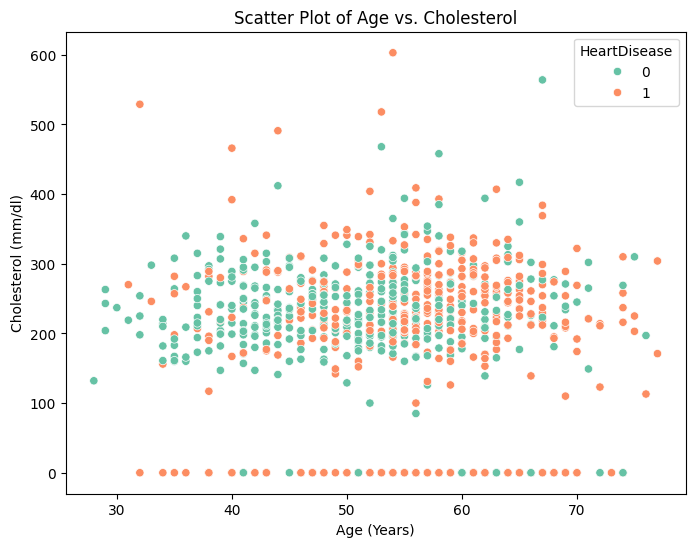

In [10]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Age', y='Cholesterol', data=df, hue='HeartDisease', palette='Set2')
plt.title('Scatter Plot of Age vs. Cholesterol')
plt.xlabel('Age (Years)')
plt.ylabel('Cholesterol (mm/dl)')
plt.show()

**4. Exploring Multiple Variables (Scatter Plot)**
* **Description:** The scatter plot explores the relationship between `Age` and `Cholesterol`, colored by the presence of heart disease.
* **Why Preprocessing is needed:** Looking at the axes, `Age` ranges roughly from 28 to 77, whereas `Cholesterol` jumps from 0 to over 600. This massive difference in numerical scales (tens vs. hundreds) can negatively impact distance-based algorithms like K-Means clustering. This clearly justifies the need for **Data Normalization (Scaling)** to bring all numeric features to a standard scale.

---
# **[4] Data Preprocessing**


## 2. Data Preprocessing
Based on the insights gained from the Data Analysis section, we applied three different preprocessing techniques.

### 2.1 Technique 1: Noise Removal

*   **Justification and Results:**
Cholesterol (172 records) and RestingBP (1 record) had values of 0, which are biologically impossible, so they were replaced with the median of each attribute. Extreme outliers in Age, RestingBP, Cholesterol, MaxHR, and Oldpeak were filtered out using the Z-score method (with a threshold of 3 standard deviations) to ensure data quality. After cleaning and removing extreme outliers, the dataset size was adjusted from 918 to 890 records, leaving a clean and reliable dataset.

In [11]:
import numpy as np
from scipy.stats import zscore

# Work on a copy so the raw dataset (df) stays unchanged
df_preprocessed = df.copy()

# Step 1: Replace impossible zero values with NaN, then impute with the median
for col in ['RestingBP', 'Cholesterol']:
    df_preprocessed[col] = df_preprocessed[col].replace(0, np.nan)

print("Impossible zero values found:")
print(df_preprocessed[['RestingBP', 'Cholesterol']].isna().sum())

medians = df_preprocessed[['RestingBP', 'Cholesterol']].median()
df_preprocessed[['RestingBP', 'Cholesterol']] = df_preprocessed[['RestingBP', 'Cholesterol']].fillna(medians)

print("\nMedians used for imputation:")
print(medians)

# Step 2: Apply Z-Score on numerical columns to remove extreme outliers
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Calculate the z-score for all numerical columns
z_scores = np.abs(zscore(df_preprocessed[numeric_cols]))

# Keep only the rows that fall within the normal range (less than 3 standard deviations)
df_preprocessed = df_preprocessed[(z_scores < 3).all(axis=1)]

print("\nNew shape after Z-score outlier removal:", df_preprocessed.shape)

# Correlation check
print("\nCorrelation of Cholesterol with HeartDisease:")
print("before: ", df['Cholesterol'].corr(df['HeartDisease']))
print("after : ", df_preprocessed['Cholesterol'].corr(df_preprocessed['HeartDisease']))


Impossible zero values found:
RestingBP        1
Cholesterol    172
dtype: int64

Medians used for imputation:
RestingBP      130.0
Cholesterol    237.0
dtype: float64

New shape after Z-score outlier removal: (890, 12)

Correlation of Cholesterol with HeartDisease:
before:  -0.23274063892701105
after :  0.0787086241969746


### 2.2 Technique 2: Discretization
* **Justification and Results:** Age is a continuous numerical attribute. Discretization was applied to divide Age into meaningful age groups: ≤30, 31–40, 41–50, 51–60, 61–70, and >70. This makes the data easier to interpret and allows patterns across different age ranges to be analyzed more clearly. A new categorical attribute, Age_Group, was created while preserving the original Age attribute.

In [12]:
# Discretization of Age

# Define age intervals
bins = [0, 30, 40, 50, 60, 70, 100]
labels = ['≤30', '31-40', '41-50', '51-60', '61-70', '>70']

# Apply discretization to Age and save it in a NEW column (Age_Group)
df_preprocessed['Age_Group'] = pd.cut(
    df_preprocessed['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Show the result before and after discretization
print("Age before discretization (Original):")
print(df['Age'].head(10))

print("\nAge after discretization (New Column):")
print(df_preprocessed['Age_Group'].head(10))

# Show the number of patients in each age group
print("\nNumber of patients in each age group:")
print(df_preprocessed['Age_Group'].value_counts().sort_index())


Age before discretization (Original):
0    40
1    49
2    37
3    48
4    54
5    39
6    45
7    54
8    37
9    48
Name: Age, dtype: int64

Age after discretization (New Column):
0    31-40
1    41-50
2    31-40
3    41-50
4    51-60
5    31-40
6    41-50
7    51-60
8    31-40
9    41-50
Name: Age_Group, dtype: category
Categories (6, object): ['≤30' < '31-40' < '41-50' < '51-60' < '61-70' < '>70']

Number of patients in each age group:
Age_Group
≤30        5
31-40     85
41-50    219
51-60    367
61-70    190
>70       24
Name: count, dtype: int64


### 2.3 Technique 3: Data Normalization (Scaling)

*  **Justification and Results:**
Min-Max Normalization was applied to all numeric attributes (Age, RestingBP, Cholesterol, MaxHR, and Oldpeak) using MinMaxScaler. These attributes have different numerical ranges, so scaling them to [0, 1] makes them comparable and reduces the influence of their original scales. The before-and-after results show that all these attributes were successfully normalized.

In [13]:
from sklearn.preprocessing import MinMaxScaler

# Select numerical columns for normalization
columns_to_scale = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Save original values before normalization
before_scaling = df_preprocessed[columns_to_scale].copy()

# Apply Min-Max Normalization
scaler = MinMaxScaler()

df_preprocessed[columns_to_scale] = scaler.fit_transform(
df_preprocessed[columns_to_scale]
)

# Display values before and after normalization
print("Before Normalization:")
print(before_scaling.head(10))

print("\nAfter Normalization:")
print(df_preprocessed[columns_to_scale].head(10))


Before Normalization:
   Age  RestingBP  Cholesterol  MaxHR  Oldpeak
0   40      140.0        289.0    172      0.0
1   49      160.0        180.0    156      1.0
2   37      130.0        283.0     98      0.0
3   48      138.0        214.0    108      1.5
4   54      150.0        195.0    122      0.0
5   39      120.0        339.0    170      0.0
6   45      130.0        237.0    170      0.0
7   54      110.0        208.0    142      0.0
8   37      140.0        207.0    130      1.5
9   48      120.0        284.0    120      0.0

After Normalization:
        Age  RestingBP  Cholesterol     MaxHR   Oldpeak
0  0.244898   0.571429     0.660194  0.784173  0.333333
1  0.428571   0.761905     0.307443  0.669065  0.500000
2  0.183673   0.476190     0.640777  0.251799  0.333333
3  0.408163   0.552381     0.417476  0.323741  0.583333
4  0.530612   0.666667     0.355987  0.424460  0.333333
5  0.224490   0.380952     0.822006  0.769784  0.333333
6  0.346939   0.476190     0.491909  0.769784  

### 2.4 Final SnapShot

In [14]:
print("Snapshot of the RAW dataset:")
display(df.head(10))

print("Snapshot of the PREPROCESSED dataset:")
display(df_preprocessed.head(10))

print("Raw shape:", df.shape, "| Preprocessed shape:", df_preprocessed.shape)

df_preprocessed.to_csv('Preprocessed_dataset.csv', index=False)
print("Saved as Preprocessed_dataset.csv")

Snapshot of the RAW dataset:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


Snapshot of the PREPROCESSED dataset:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Age_Group
0,0.244898,M,ATA,0.571429,0.660194,0,Normal,0.784173,N,0.333333,Up,0,31-40
1,0.428571,F,NAP,0.761905,0.307443,0,Normal,0.669065,N,0.500000,Flat,1,41-50
2,0.183673,M,ATA,0.476190,0.640777,0,ST,0.251799,N,0.333333,Up,0,31-40
3,0.408163,F,ASY,0.552381,0.417476,0,Normal,0.323741,Y,0.583333,Flat,1,41-50
4,0.530612,M,NAP,0.666667,0.355987,0,Normal,0.424460,N,0.333333,Up,0,51-60
5,0.224490,M,NAP,0.380952,0.822006,0,Normal,0.769784,N,0.333333,Up,0,31-40
6,0.346939,F,ATA,0.476190,0.491909,0,Normal,0.769784,N,0.333333,Up,0,41-50
7,0.530612,M,ATA,0.285714,0.398058,0,Normal,0.568345,N,0.333333,Up,0,51-60
8,0.183673,M,ASY,0.571429,0.394822,0,Normal,0.482014,Y,0.583333,Flat,1,31-40
9,0.408163,F,ATA,0.380952,0.644013,0,Normal,0.410072,N,0.333333,Up,0,41-50


Raw shape: (918, 12) | Preprocessed shape: (890, 13)
Saved as Preprocessed_dataset.csv


---
# **[5] Data Mining Technique**
## **Phase 3:** Data Mining

## 5.1 Classification and Clustering Techniques

**1. Classification: Decision Tree**

We use Decision Tree classification to predict whether a patient has heart disease (HeartDisease = 1) or not (HeartDisease = 0). It was chosen because it produces clear, interpretable rules that show which clinical attributes affect the diagnosis. We apply two attribute selection measures (Gini Index and Information Gain) on three partition sizes (90/10, 80/20, 70/30).

**Packages and methods:** `DecisionTreeClassifier` (sklearn.tree), `train_test_split` (sklearn.model_selection), `accuracy_score`, `confusion_matrix` and `ConfusionMatrixDisplay` (sklearn.metrics), and `plot_tree` (sklearn.tree).

**2. Clustering: K-means**

We use K-means to group patients with similar clinical profiles without using the class label, to discover hidden patient segments. It was chosen because it is simple and efficient for numeric, normalized data. We evaluate at least three values of K.

**Packages and methods:** `KMeans` (sklearn.cluster), `silhouette_score` and `calinski_harabasz_score` (sklearn.metrics), `inertia_` for the Elbow method (total within-cluster sum of squares), `SilhouetteVisualizer` (yellowbrick.cluster), `scatterplot` (seaborn) to visualize the clusters, and `groupby` (pandas) to describe each cluster.

**Data preparation:** Categorical attributes are encoded using `LabelEncoder` and scaled to [0, 1] using `MinMaxScaler` (sklearn.preprocessing), since scikit-learn [3] accepts only numerical data.

## 5.2 Data Preparation

### 5.2.1 Loading Data



In [15]:
df = pd.read_csv('Preprocessed_dataset.csv')
# Age_Group was created from Age (discretization), so it has the same information as Age
# We drop it to avoid using the same feature twice in the models
df = df.drop('Age_Group', axis=1)
print(df.head())

        Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
0  0.244898   M           ATA   0.571429     0.660194          0     Normal   
1  0.428571   F           NAP   0.761905     0.307443          0     Normal   
2  0.183673   M           ATA   0.476190     0.640777          0         ST   
3  0.408163   F           ASY   0.552381     0.417476          0     Normal   
4  0.530612   M           NAP   0.666667     0.355987          0     Normal   

      MaxHR ExerciseAngina   Oldpeak ST_Slope  HeartDisease  
0  0.784173              N  0.333333       Up             0  
1  0.669065              N  0.500000     Flat             1  
2  0.251799              N  0.333333       Up             0  
3  0.323741              Y  0.583333     Flat             1  
4  0.424460              N  0.333333       Up             0  


### 5.2.2 Encoding Categorical Data

In [16]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])
df['ChestPainType'] = le.fit_transform(df['ChestPainType'])
df['RestingECG'] = le.fit_transform(df['RestingECG'])
df['ExerciseAngina'] = le.fit_transform(df['ExerciseAngina'])
df['ST_Slope'] = le.fit_transform(df['ST_Slope'])
print(df.head())

        Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  \
0  0.244898    1              1   0.571429     0.660194          0   
1  0.428571    0              2   0.761905     0.307443          0   
2  0.183673    1              1   0.476190     0.640777          0   
3  0.408163    0              0   0.552381     0.417476          0   
4  0.530612    1              2   0.666667     0.355987          0   

   RestingECG     MaxHR  ExerciseAngina   Oldpeak  ST_Slope  HeartDisease  
0           1  0.784173               0  0.333333         2             0  
1           1  0.669065               0  0.500000         1             1  
2           2  0.251799               0  0.333333         2             0  
3           1  0.323741               1  0.583333         1             1  
4           1  0.424460               0  0.333333         2             0  


### 5.2.3 Normalization

In [17]:
# Extract columns to normalize
columns_to_normalize = ['ChestPainType', 'RestingECG', 'ST_Slope']
data_to_normalize = df[columns_to_normalize]

# Min-Max scaling for selected columns
minmax_scaler = MinMaxScaler()
normalized_data_minmax = minmax_scaler.fit_transform(data_to_normalize)

# Replace the normalized values in the original DataFrame
df[columns_to_normalize] = normalized_data_minmax
print(df.head())

        Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  \
0  0.244898    1       0.333333   0.571429     0.660194          0   
1  0.428571    0       0.666667   0.761905     0.307443          0   
2  0.183673    1       0.333333   0.476190     0.640777          0   
3  0.408163    0       0.000000   0.552381     0.417476          0   
4  0.530612    1       0.666667   0.666667     0.355987          0   

   RestingECG     MaxHR  ExerciseAngina   Oldpeak  ST_Slope  HeartDisease  
0         0.5  0.784173               0  0.333333       1.0             0  
1         0.5  0.669065               0  0.500000       0.5             1  
2         1.0  0.251799               0  0.333333       1.0             0  
3         0.5  0.323741               1  0.583333       0.5             1  
4         0.5  0.424460               0  0.333333       1.0             0  


### 5.2.4 Feature Selection

In [18]:
#split dataset in features and target variable
fn = df.keys().tolist()[:-1]  #df columns names without last column 'HeartDisease'
X = df[fn]  # Features names
y = df['HeartDisease']  # Target variable

---
# **[6] Evaluation and Comparison**
## 6.1 Classification

### 6.1.1 Decision Tree – Gini Index

In [19]:
# Load libraries
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

#### Gini Index – 90% Training / 10% Testing

Accuracy: 0.7752808988764045
[[29 11]
 [ 9 40]]


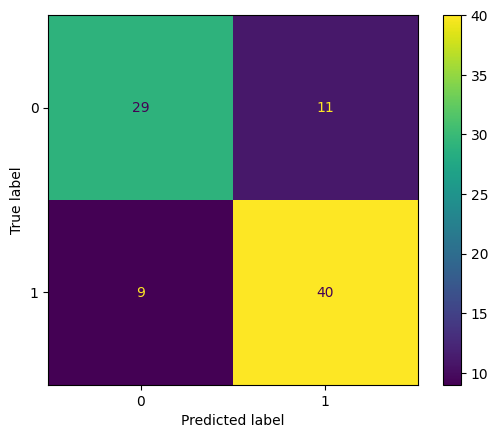

In [20]:
cn=df['HeartDisease'].unique() #classes_names
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1) # 90% training and 10% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

#### Gini Index – 80% Training / 20% Testing

Accuracy: 0.7359550561797753
[[58 22]
 [25 73]]


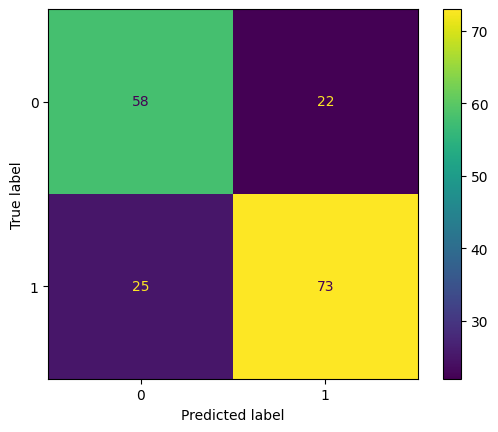

In [21]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1) # 80% training and 20% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

#### Gini Index – 70% Training / 30% Testing

Accuracy: 0.7715355805243446
[[ 86  29]
 [ 32 120]]


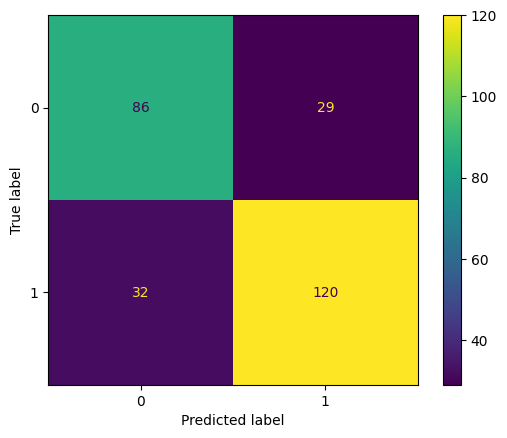

In [22]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

### 6.1.2 Decision Tree – Information Gain (Entropy)


#### Information Gain (Entropy) – 90% Training / 10% Testing


Accuracy: 0.7078651685393258
[[28 12]
 [14 35]]


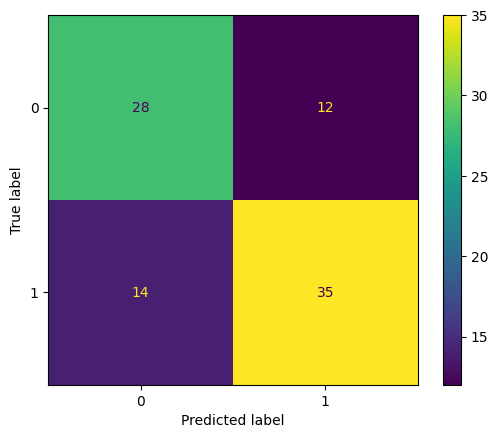

In [23]:

# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1) # 90% training and 10% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion="entropy",random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

#### Information Gain (Entropy) – 80% Training / 20% Testing


Accuracy: 0.7584269662921348
[[58 22]
 [21 77]]


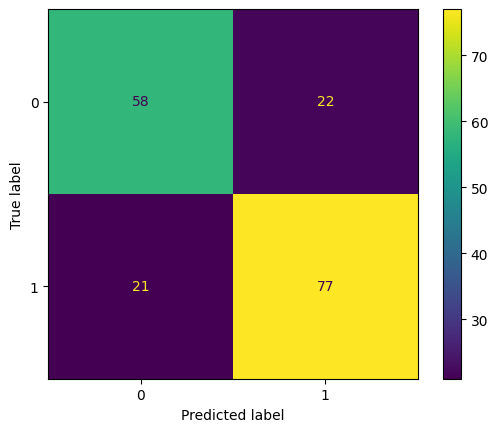

In [24]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1) # 80% training and 20% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion="entropy",random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

#### Information Gain (Entropy) – 70% Training / 30% Testing


Accuracy: 0.7640449438202247
[[ 85  30]
 [ 33 119]]


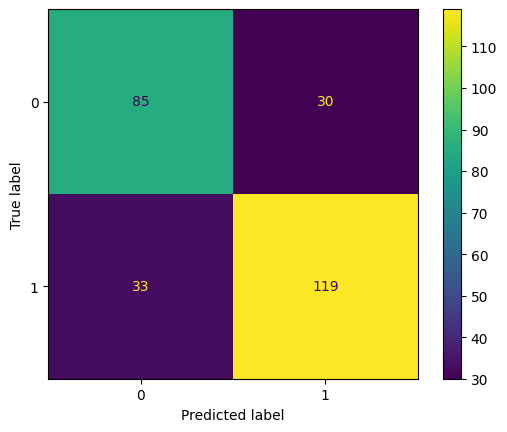

In [25]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion="entropy",random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

### 6.1.3 Classification Comparison

#### Accuracy Table

In [26]:
# Accuracy of Gini Index and Information Gain for each partition
accuracy_table = pd.DataFrame({
'Attribute Selection Measure': ['Gini Index', 'Information Gain'],
'90% training set 10% testing set': [0.7753, 0.7079],
'80% training set 20% testing set': [0.7360, 0.7584],
'70% training set 30% testing set': [0.7715, 0.7640]
})
print(accuracy_table)

  Attribute Selection Measure  90% training set 10% testing set  \
0                  Gini Index                            0.7753   
1            Information Gain                            0.7079   

   80% training set 20% testing set  70% training set 30% testing set  
0                            0.7360                            0.7715  
1                            0.7584                            0.7640  


#### Accuracy Comparison Chart

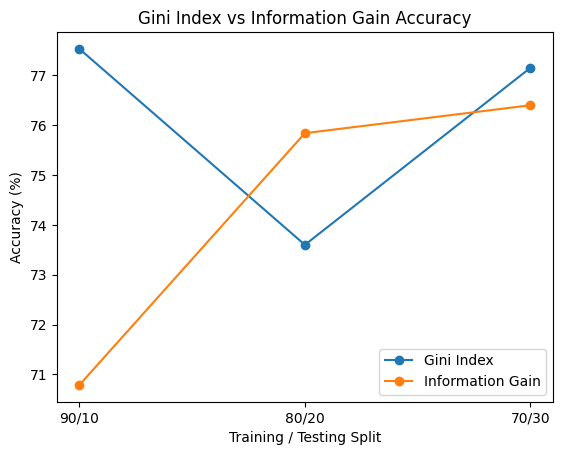

In [27]:
# Compare Gini Index and Information Gain accuracy for each partition
partitions = ['90/10', '80/20', '70/30']
plt.plot(partitions, [77.53, 73.60, 77.15], marker='o', label='Gini Index')
plt.plot(partitions, [70.79, 75.84, 76.40], marker='o', label='Information Gain')
plt.title('Gini Index vs Information Gain Accuracy')
plt.xlabel('Training / Testing Split')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

#### Classification Results Discussion

The classification results show that Gini Index achieved higher accuracy than Information Gain for the 90/10 and 70/30 partitions, with accuracies of 77.53% and 77.15%, respectively. However, Information Gain performed better for the 80/20 partition, achieving 75.84% accuracy compared to 73.60% for Gini Index.

Overall, Gini Index with 90% training and 10% testing achieved the highest accuracy of 77.53% among all six experiments. Therefore, it was selected as the best-performing model based on accuracy.

## 6.2 Clustering

### Elbow Method

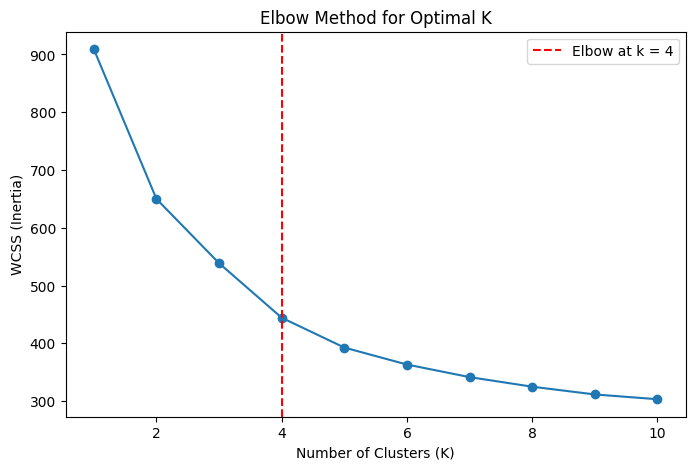

In [28]:
# Elbow Method (Total Within-Cluster Sum of Squares)
from sklearn.cluster import KMeans
# Use the already prepared and normalized features
X_clustering = X
# Calculate WCSS for different values of K
wcss = []
k_values = range(1, 11)
for k in k_values:
 # n_init=10 runs K-means 10 times with different starting centers and keeps the best result
 kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
 kmeans.fit(X_clustering)
 wcss.append(kmeans.inertia_)
# Plot the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method for Optimal K')
plt.axvline(x=4, linestyle='--', color='red', label='Elbow at k = 4')
plt.legend()
plt.show()

The Elbow Method helps identify the optimal number of clusters by examining the WCSS values. WCSS decreases as the number of clusters increases. The best K is estimated at the point where the decrease starts to slow down.

### Silhouette Coefficient and Calinski-Harabasz Index for a Range of K

Silhouette scores: [np.float64(0.2842831209105925), np.float64(0.29745612266766), np.float64(0.3071737015756118), np.float64(0.33386872110899624), np.float64(0.34684162789019346), np.float64(0.2832140469217733), np.float64(0.24306884440436566), np.float64(0.23753532283046583), np.float64(0.24476445631406857)]
Calinski-Harabasz scores: [np.float64(354.1325571929677), np.float64(304.9044864928644), np.float64(308.9294205705276), np.float64(290.9211941230893), np.float64(265.5577376488067), np.float64(244.52019752036037), np.float64(226.44652840573255), np.float64(211.20595334874872), np.float64(195.2775122395334)]


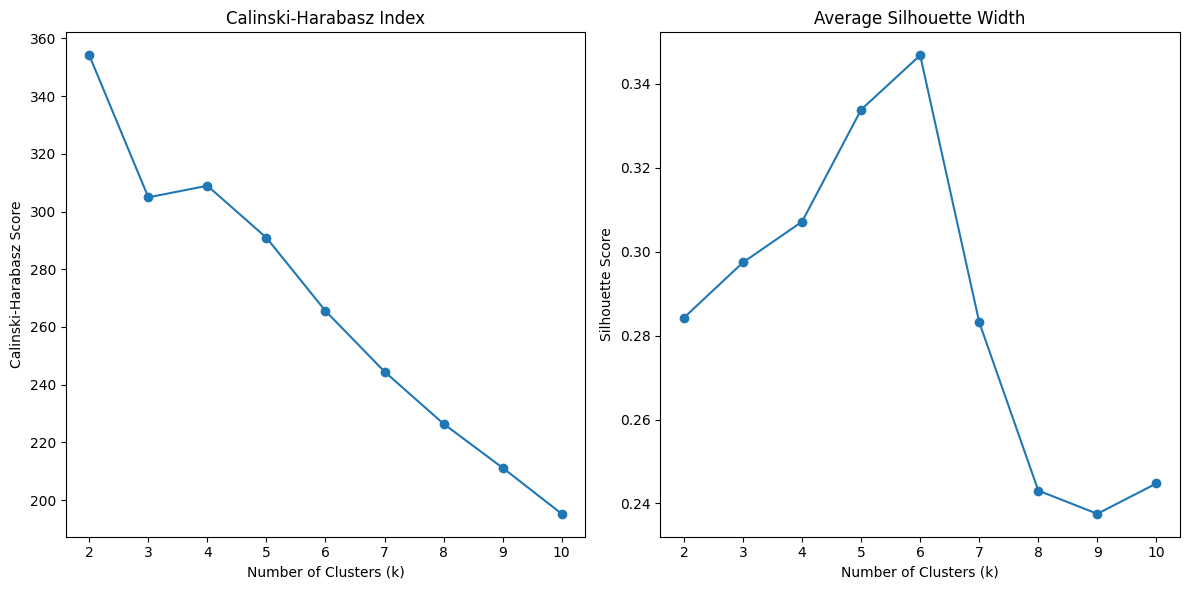

In [29]:
from sklearn.metrics import calinski_harabasz_score, silhouette_score
# Range of clusters to try
k_range = range(2, 11)
# Lists to store scores
ch_scores = []
silhouette_scores = []
# Calculate scores for each value of k
for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_clustering)
  ch_score = calinski_harabasz_score(X_clustering, kmeans.labels_)
  silhouette_avg = silhouette_score(X_clustering, kmeans.labels_)
  ch_scores.append(ch_score)
  silhouette_scores.append(silhouette_avg)
print("Silhouette scores:", silhouette_scores)
print("Calinski-Harabasz scores:", ch_scores)
# Plotting results
plt.figure(figsize=(12, 6))
# Plot Calinski-Harabasz Index
plt.subplot(1, 2, 1)
plt.plot(k_range, ch_scores, marker='o')
plt.title('Calinski-Harabasz Index')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Calinski-Harabasz Score')
# Plot Average Silhouette Width
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='o')
plt.title('Average Silhouette Width')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

The Silhouette Score measures how well the data points fit within their clusters compared to other clusters. A higher score indicates better-defined clusters. In our results, K = 6 achieved the highest score of 0.3468.

The Calinski-Harabasz Index evaluates the ratio of the between-cluster variance to the within-cluster variance. A higher value indicates well-separated and compact clusters. Among K = 4, 5 and 6, K = 4 achieved the highest Calinski-Harabasz score (308.9).




### Chosen K Values & Justification

The Elbow plot shows that WCSS drops sharply up to K = 4, after which the decrease becomes much smaller (from 94.4 between K = 3 and K = 4 to 51.6 between K = 4 and K = 5), so the elbow is at K = 4. The Silhouette Score is highest at K = 6 (0.3468), followed by K = 5 (0.3339). Therefore, K = 4, K = 5 and K = 6 were selected for further evaluation.

### Silhouette Plot – K value #1

In [30]:
%pip install yellowbrick

The average silhouette score is: 0.3071737015756118


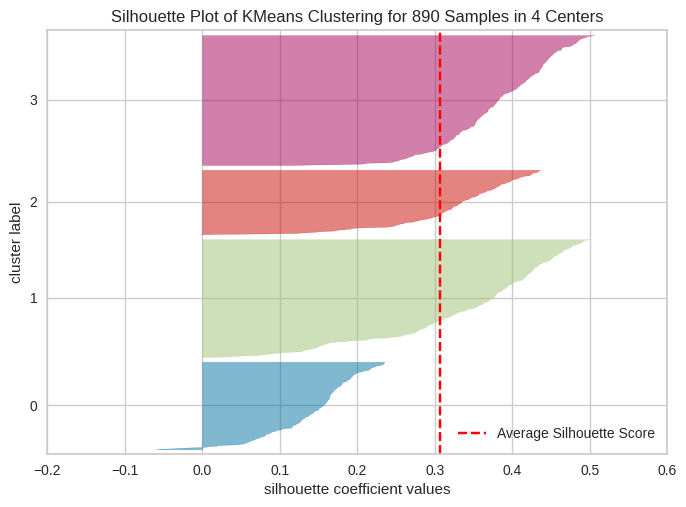

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 890 Samples in 4 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [31]:
from yellowbrick.cluster import SilhouetteVisualizer
# Silhouette Plot for K = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors='yellowbrick')
visualizer.fit(X_clustering)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()

The average silhouette score for K = 4 is 0.3072. Clusters 1, 2 and 3 have similar silhouette values (0.32–0.38), but Cluster 0 has a much lower average (0.14) and contains 5 of the 6 points with negative silhouette values. This means Cluster 0 is less compact and some of its patients are closer to other clusters.

### Silhouette Plot – K value #2

The average silhouette score is: 0.33386872110899624


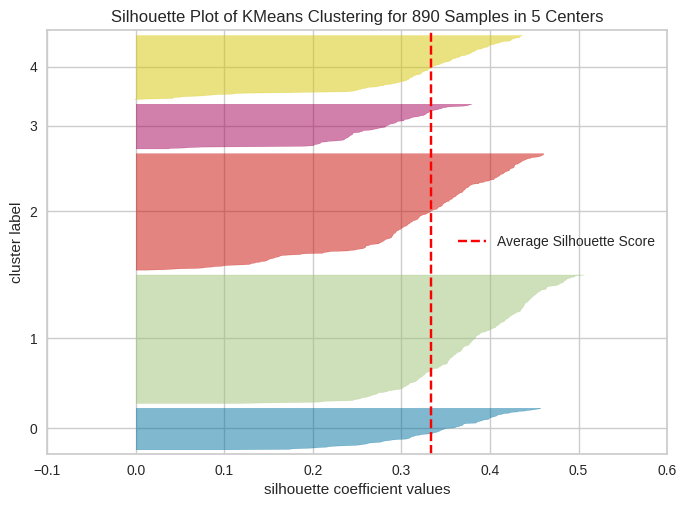

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 890 Samples in 5 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [32]:
# Silhouette Plot for K = 5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors='yellowbrick')
visualizer.fit(X_clustering)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()

The average silhouette score increases to 0.3339 for K = 5. The weak cluster from K = 4 is split, so all clusters now have an average silhouette value between 0.27 and 0.38, and only one point has a negative value. This indicates more balanced and better-separated clusters than K = 4.

### Silhouette Plot – K value #3

The average silhouette score is: 0.34684162789019346


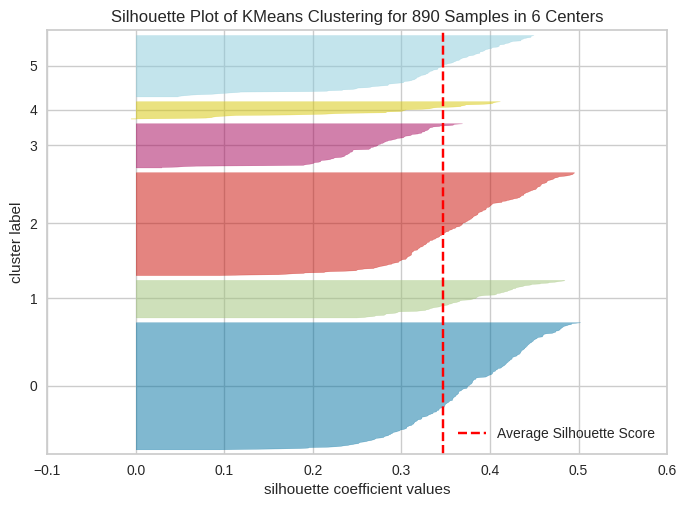

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 890 Samples in 6 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [33]:
# Silhouette Plot for K = 6
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
visualizer = SilhouetteVisualizer(kmeans, colors='yellowbrick')
visualizer.fit(X_clustering)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show()


K = 6 achieved the highest average silhouette score (0.3468). All six clusters have average silhouette values between 0.26 and 0.38, with only one negative point. However, the improvement over K = 5 is small, and K = 6 creates a very small cluster of only 40 patients.

### Clustering Table

In [34]:
# Clustering table for the three chosen values of K
clustering_table = pd.DataFrame({
'Metric': ['Average Silhouette width', 'Total within-cluster sum of square'],
'K=4': [0.3072, 444.26],
'K=5': [0.3339, 392.66],
'K=6': [0.3468, 363.30]
})
print(clustering_table)

                               Metric       K=4       K=5       K=6
0            Average Silhouette width    0.3072    0.3339    0.3468
1  Total within-cluster sum of square  444.2600  392.6600  363.3000


### Optimal K (Majority Rule)

| Method | Best K (among K = 4, 5, 6) |
|---|---|
| Elbow (WCSS) | K = 4 |
| Silhouette Coefficient | K = 6 (0.3468) |
| Calinski-Harabasz Index | K = 4 (308.9) |

Two of the three methods select K = 4. Therefore, based on the majority rule, the optimal number of clusters is K = 4.


### K-means Clustering – K = 4

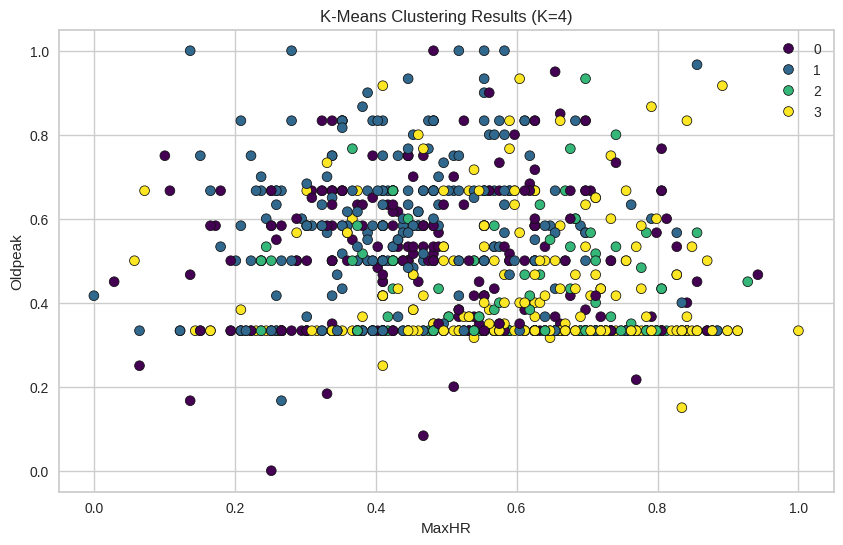

In [35]:
# Run k-means clustering with K = 4
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_result_4 = kmeans_4.fit(X_clustering)

# Add the cluster labels to a COPY of X
X_k4 = X_clustering.copy()
X_k4['Cluster'] = kmeans_result_4.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='MaxHR', y='Oldpeak', hue='Cluster', data=X_k4,
                palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=4)')
plt.xlabel('MaxHR')
plt.ylabel('Oldpeak')
plt.legend()
plt.show()

With K = 4, the patients are divided into four groups that differ mainly in Sex, ExerciseAngina, and FastingBS. In the MaxHR vs. Oldpeak plot the clusters overlap, but the clusters with exercise angina tend to have lower MaxHR and higher Oldpeak.

### K-means Clustering – K = 5

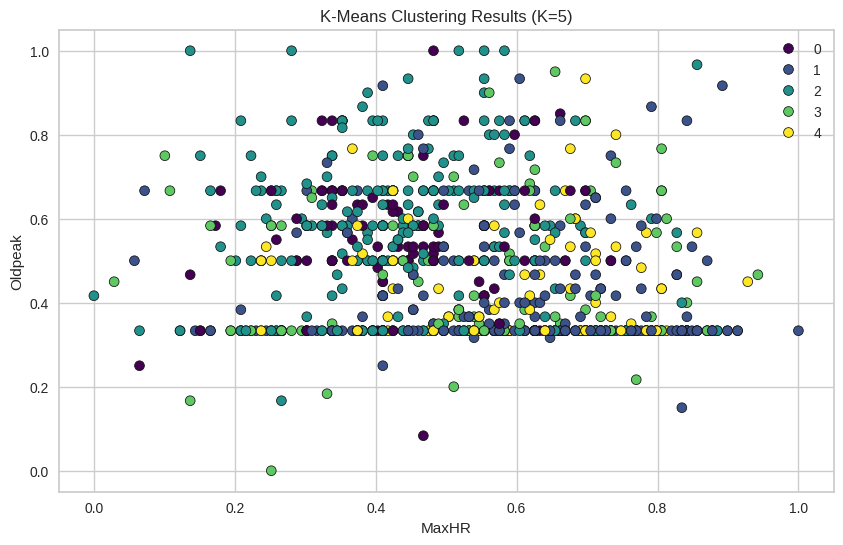

In [36]:
# Run k-means clustering with K = 5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_result_5 = kmeans_5.fit(X_clustering)

# Add the cluster labels to a COPY of X
X_k5 = X_clustering.copy()
X_k5['Cluster'] = kmeans_result_5.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='MaxHR', y='Oldpeak', hue='Cluster', data=X_k5,
                palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=5)')
plt.xlabel('MaxHR')
plt.ylabel('Oldpeak')
plt.legend()
plt.show()

With K = 5, the group of patients with high fasting blood sugar is split into two clusters, one with exercise angina and one without, giving more specific patient profiles. The clusters still overlap in MaxHR and Oldpeak, since the separation comes mostly from the binary attributes.

### K-means Clustering – K = 6


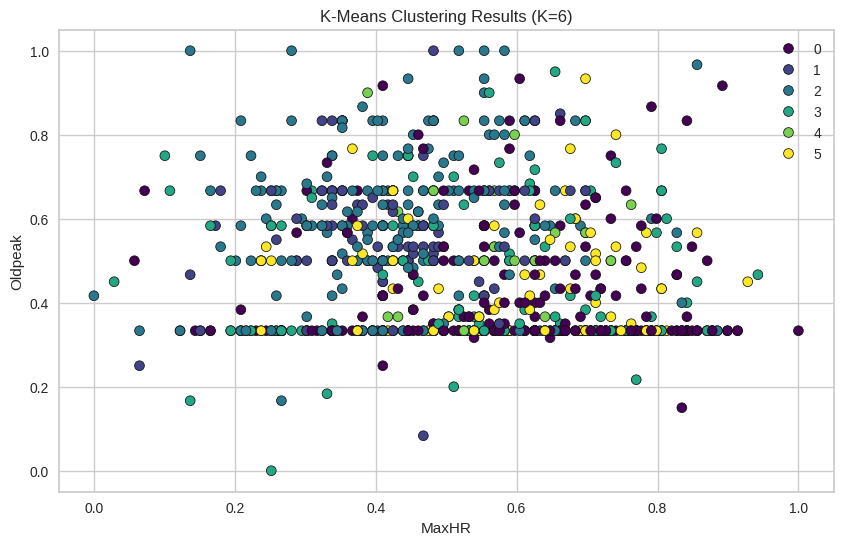

In [37]:
# Run k-means clustering with K = 6
kmeans_6 = KMeans(n_clusters=6, random_state=42, n_init=10)
kmeans_result_6 = kmeans_6.fit(X_clustering)

# Add the cluster labels to a COPY of X
X_k6 = X_clustering.copy()
X_k6['Cluster'] = kmeans_result_6.labels_

# Visualize clustering using a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='MaxHR', y='Oldpeak', hue='Cluster', data=X_k6,
                palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=6)')
plt.xlabel('MaxHR')
plt.ylabel('Oldpeak')
plt.legend()
plt.show()

With K = 6, the female patients are also split into two clusters, with and without exercise angina. K = 6 achieved the highest average silhouette score (0.3468), but based on the majority rule (Section 6.2), K = 4 was selected as the optimal number of clusters.

---
# **[7] Findings and Discussion**

### 7.1 Final Decision Tree (Best Model)

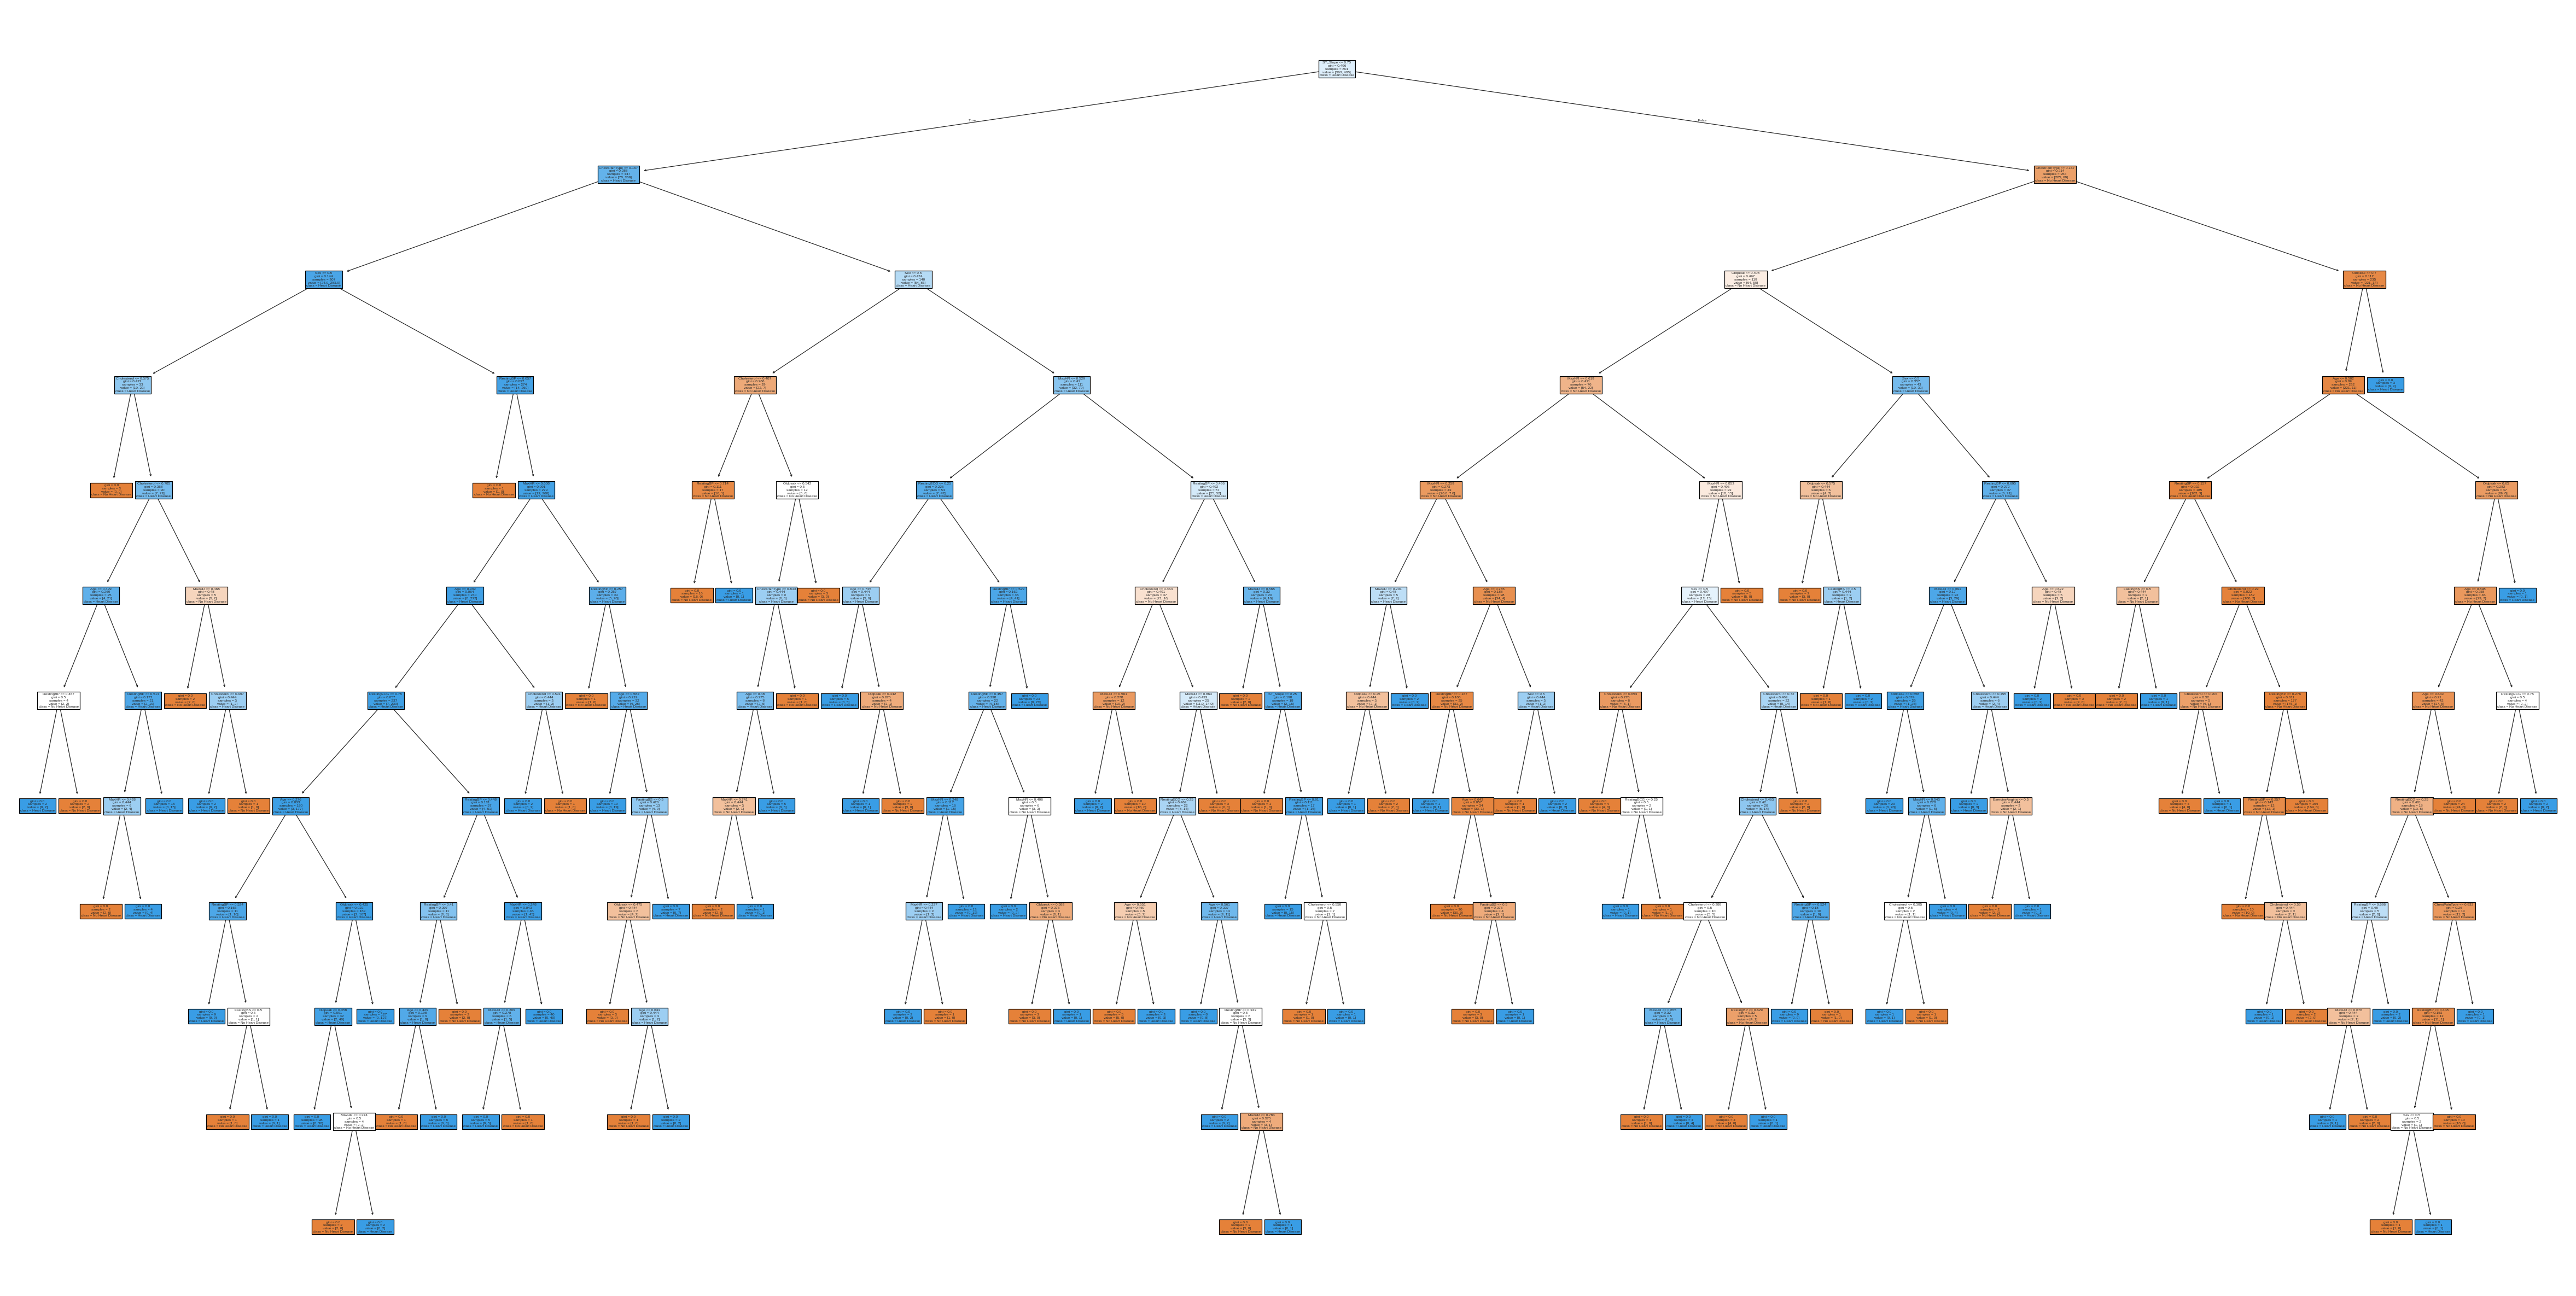

In [38]:
from sklearn import tree
# Train the best model (Gini Index – 90/10) again, because clf now holds the last model (Information Gain – 70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1) # 90% training and 10% test
clf = DecisionTreeClassifier(random_state=1)
clf = clf.fit(X_train,y_train)
# Setting dpi = 300 to make image clearer
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (20,10), dpi=300)
tree.plot_tree(clf,
feature_names = fn,
class_names=['No Heart Disease', 'Heart Disease'],
filled = True);
fig.savefig('Final_Decision_Tree.png')

The full decision tree above has 11 levels and 114 leaves, so the text inside the nodes is too small to read on screen. To clearly show and interpret the main rules, the same tree is displayed below limited to its first 3 levels using max_depth=3. This only limits what is displayed; the model itself is not changed.

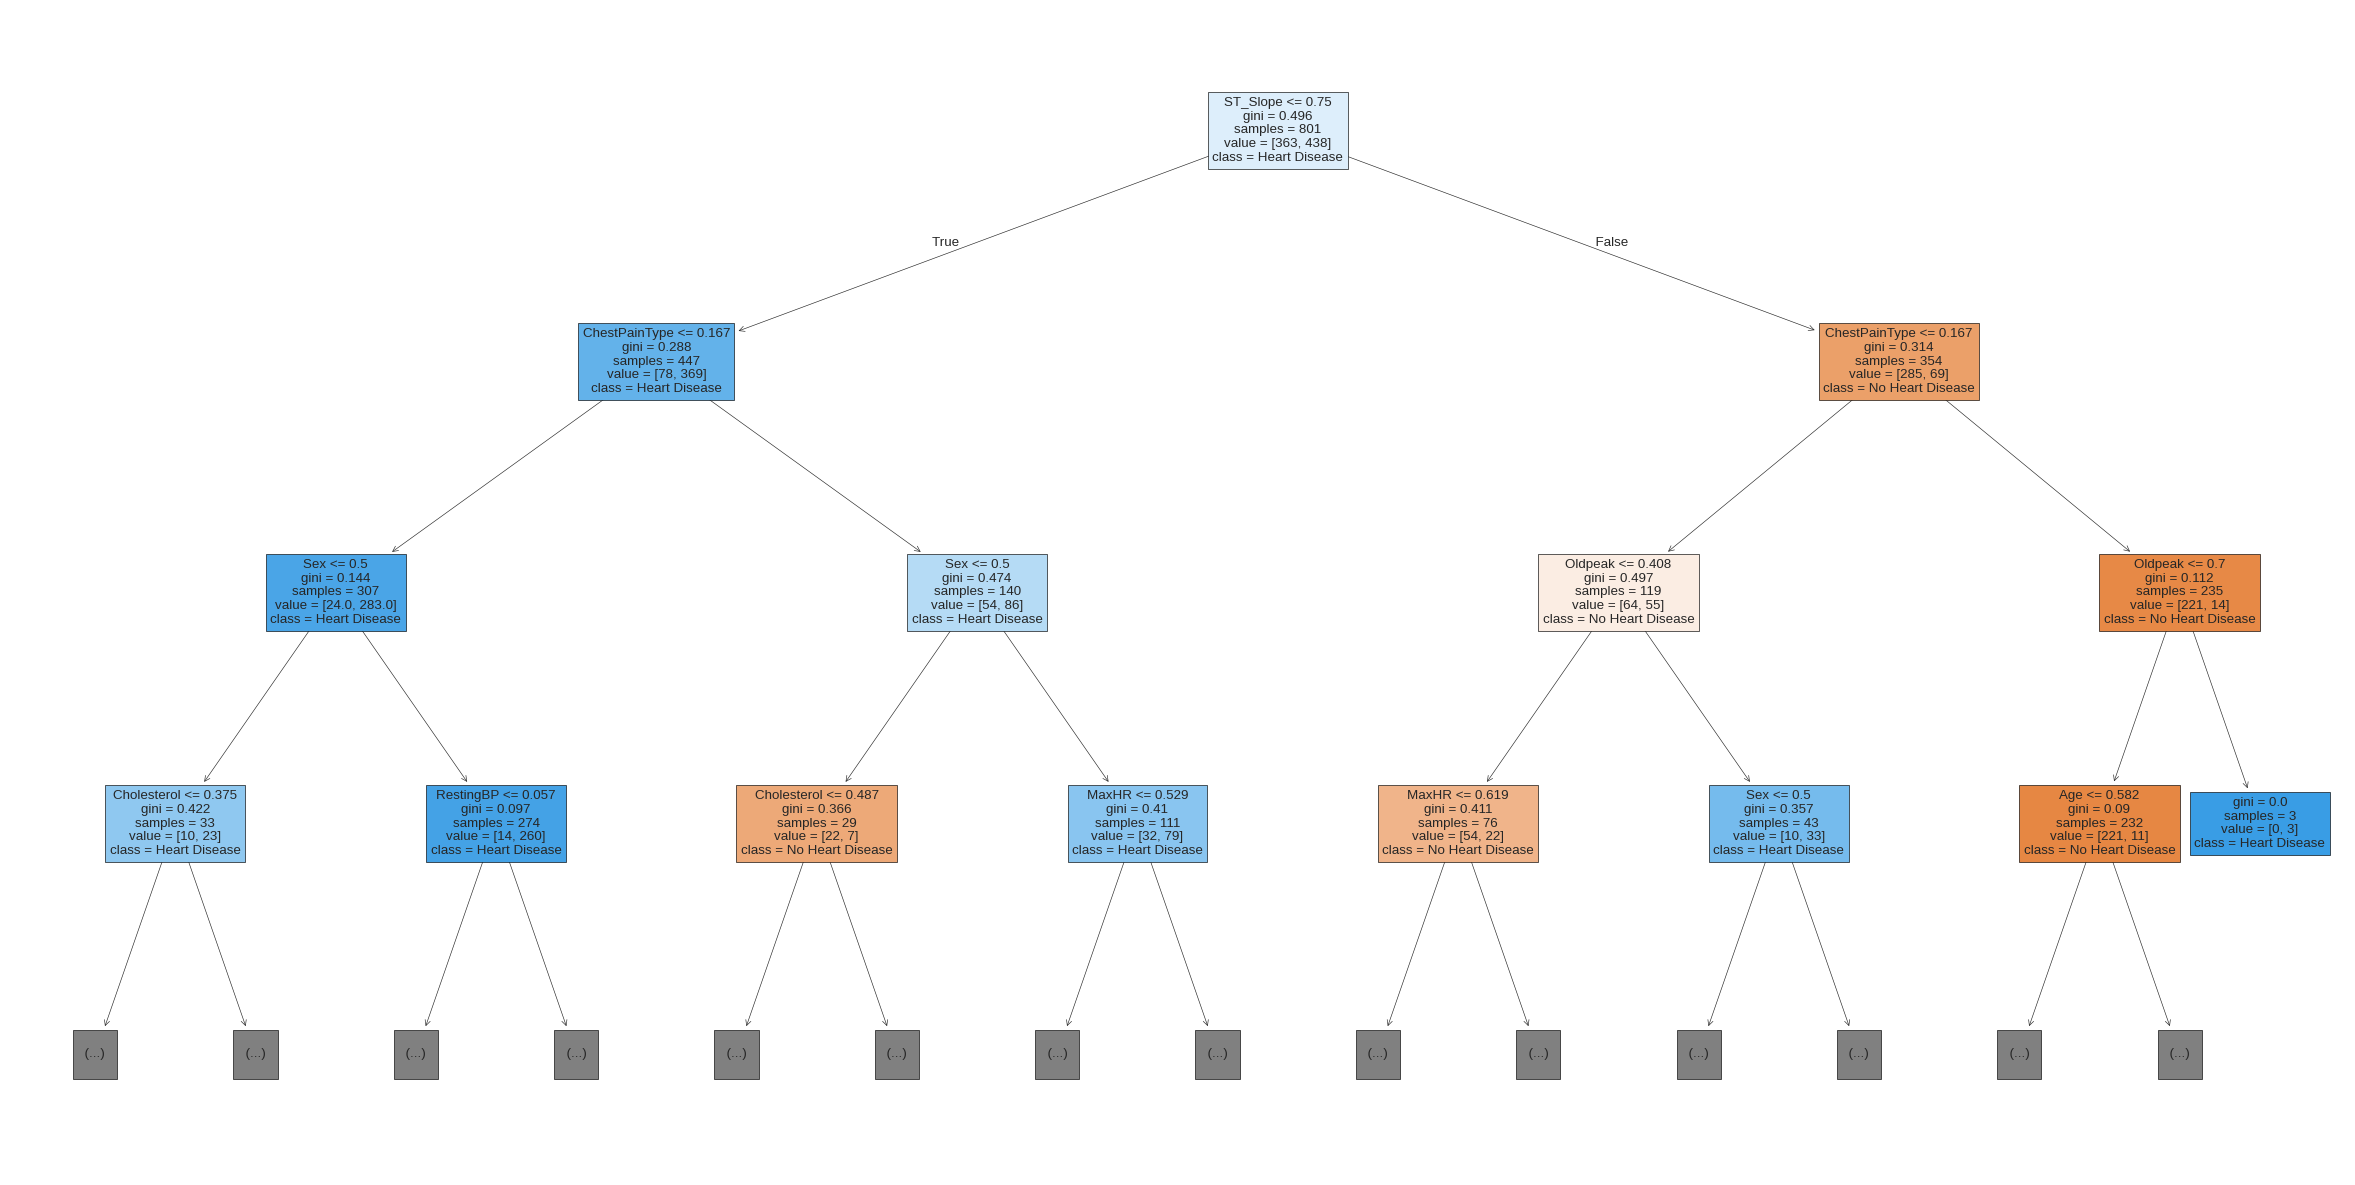

In [39]:
# Display the same tree (clf) limited to its first 3 levels so the main rules can be read
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (20,10), dpi=150)
tree.plot_tree(clf,
feature_names = fn,
class_names=['No Heart Disease', 'Heart Disease'],
filled = True,
max_depth=3);

### 7.2 Decision Tree Interpretation

The root split is ST_Slope ≤ 0.75, which separates patients with a Down or Flat ST slope (encoded 0 and 0.5) from those with an Up slope (encoded 1). 82.6% of the patients with a Down or Flat slope have heart disease, while 80.5% of those with an Up slope are normal.

At the second level, the tree splits on ChestPainType ≤ 0.17, which separates asymptomatic chest pain (ASY = 0) from the other types. Patients with a Down/Flat slope and ASY chest pain are the highest-risk group (92.2% have heart disease), while patients with an Up slope and non-ASY chest pain are the lowest-risk group (94% are normal).

Oldpeak, MaxHR and Sex appear at the next levels. This shows that ST_Slope, ChestPainType and Oldpeak are the most important attributes for predicting heart disease.

### 7.3 Cluster Characteristics

To understand what distinguishes each cluster, we examine the average value of every attribute within each cluster of the optimal K-means model (K = 4), which is the same as the cluster centers. For the binary attributes (Sex, FastingBS, ExerciseAngina), the average is the proportion of patients in the cluster with that attribute. We also add the HeartDisease rate of each cluster only to check the clusters; it was not used to build them. We then plot the clusters on MaxHR, Oldpeak, and Age, which were also among the main attributes in the final decision tree (Section 7.2).

Aggregated Data (K=4):
              Age       Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  \
Cluster                                                                         
0        0.593825  0.933333       0.203419   0.519658     0.502166   1.000000   
1        0.561614  0.893130       0.122137   0.521156     0.515687   0.000000   
2        0.474632  0.000000       0.423611   0.465146     0.515956   0.076389   
3        0.456747  1.000000       0.351788   0.469731     0.478808   0.000000   

         RestingECG     MaxHR  ExerciseAngina   Oldpeak  ST_Slope  \
Cluster                                                             
0          0.558974  0.484486        0.482051  0.504017  0.574359   
1          0.520992  0.444588        1.000000  0.570229  0.528626   
2          0.451389  0.623801        0.027778  0.409259  0.854167   
3          0.456747  0.597371        0.000000  0.406920  0.825260   

         HeartDisease  
Cluster                
0            0.820513  
1  

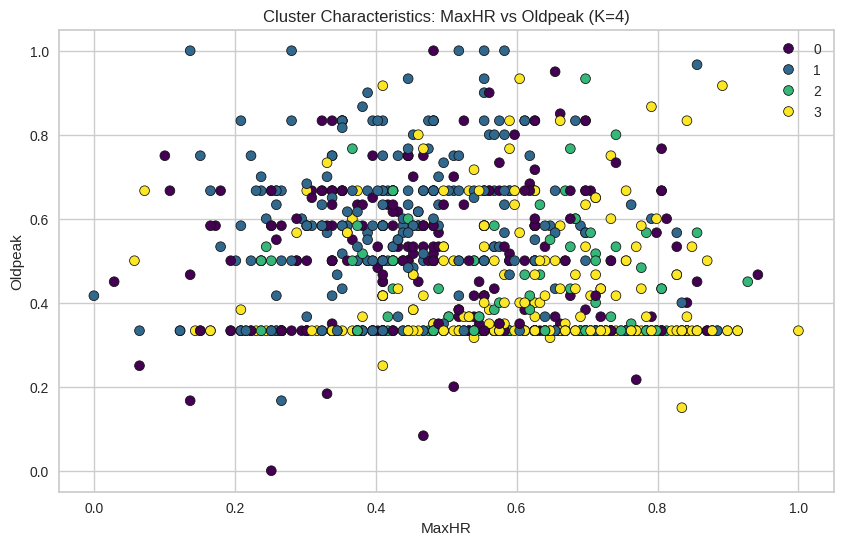

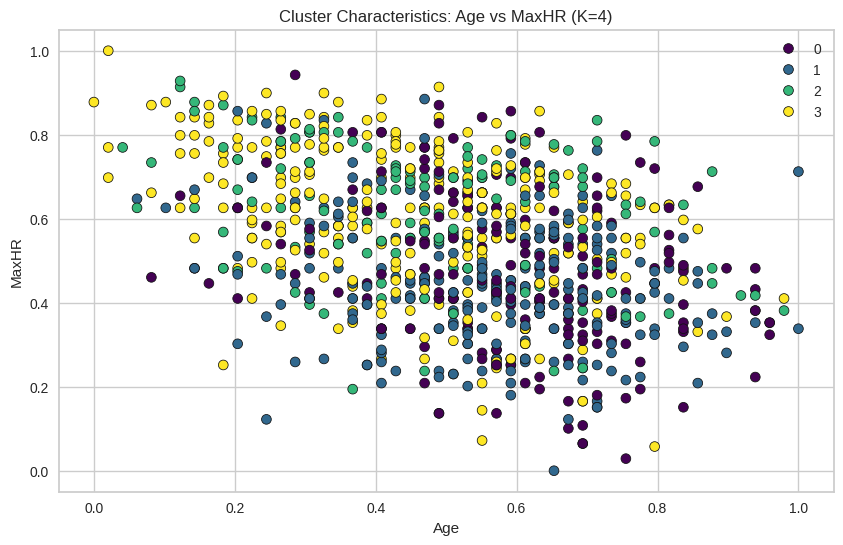

In [40]:
# Average of each attribute in each cluster (the same as the cluster centers)
# HeartDisease is added only to check the clusters, it was not used to build them
X_k4['HeartDisease'] = y
aggregated_data = X_k4.groupby('Cluster').mean()
print("Aggregated Data (K=4):")
print(aggregated_data)
# Clusters on MaxHR vs Oldpeak
plt.figure(figsize=(10, 6))
sns.scatterplot(x='MaxHR', y='Oldpeak', hue='Cluster', data=X_k4,
palette='viridis', edgecolor='k')
plt.title('Cluster Characteristics: MaxHR vs Oldpeak (K=4)')
plt.xlabel('MaxHR')
plt.ylabel('Oldpeak')
plt.legend()
plt.show()
# Clusters on Age vs MaxHR
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Age', y='MaxHR', hue='Cluster', data=X_k4,
palette='viridis', edgecolor='k')
plt.title('Cluster Characteristics: Age vs MaxHR (K=4)')
plt.xlabel('Age')
plt.ylabel('MaxHR')
plt.legend()
plt.show()

**Results:**
- The clusters are mainly separated by the binary attributes Sex, ExerciseAngina, and FastingBS.
- Clusters 0 and 1 (mostly men) have lower MaxHR (0.48 and 0.44), higher Oldpeak (0.50 and 0.57), ST_Slope closer to Flat (0.57 and 0.53), and ChestPainType close to 0 (mostly ASY). All patients in Cluster 0 have high fasting blood sugar, and all patients in Cluster 1 have exercise angina.
- Clusters 2 and 3 have almost no exercise angina, higher MaxHR (0.62 and 0.60), lower Oldpeak (0.41), and ST_Slope close to Up (0.85 and 0.83). Cluster 2 contains female patients and Cluster 3 contains male patients.
- The heart disease rate confirms this split: 82% in Cluster 0 and 83% in Cluster 1, compared to only 12% in Cluster 2 and 32% in Cluster 3.
- In the scatter plots, the clusters overlap on MaxHR and Oldpeak, because the separation comes mostly from the binary attributes.


### 7.4 Clustering Results Discussion

Using the optimal K = 4, K-means divided the 890 patients into four groups based only on their clinical attributes, without using the HeartDisease label:
- **Cluster 0 – Older men with high blood sugar (high risk):** The oldest group. Mostly male, all with high fasting blood sugar, and about half with exercise angina. They have a low MaxHR, a high Oldpeak, a mostly flat ST_Slope, and mostly asymptomatic (ASY) chest pain. 82% of them have heart disease.
- **Cluster 1 – Men with exercise angina (high risk):** Mostly male, all with exercise angina and normal fasting blood sugar. They have the lowest MaxHR, the highest Oldpeak, a flat ST_Slope, and mostly ASY chest pain. 83% of them have heart disease.
- **Cluster 2 – Women without angina (lowest risk):** Female patients with no exercise angina, the highest MaxHR, a low Oldpeak, and a mostly upsloping ST_Slope. Only 12% of them have heart disease.
- **Cluster 3 – Younger men without angina (lower risk):** The largest and youngest group. Male patients with no exercise angina and normal fasting blood sugar, a high MaxHR, a low Oldpeak, and a mostly upsloping ST_Slope. 32% of them have heart disease.

**What this means for the problem:** Without using the diagnosis, the clusters separate patients into two high-risk groups (Clusters 0 and 1) and two lower-risk groups (Clusters 2 and 3). The high-risk groups share exercise angina or high blood sugar, low MaxHR, high Oldpeak, a flat ST_Slope, and asymptomatic chest pain. These are the same attributes the decision tree relied on (ST_Slope, ChestPainType, Oldpeak, MaxHR; see Section 7.2), so the two techniques support each other. This segmentation could help doctors identify patient groups that need closer screening.

**Limitations:** Because Sex, ExerciseAngina, and FastingBS take only the values 0 or 1, they have a strong influence on the distance calculation, so the clusters are split largely by these attributes. As a result, the clusters overlap in the MaxHR vs. Oldpeak plots, and the average silhouette score (0.3072) is close to 0, which indicates moderate overlap between the clusters.

### 7.5 Research Paper Comparison



We compared our results with the study by Mahmud et al. [4], which used the same Kaggle dataset [2] (918 records, 11 clinical features) to predict heart disease.

| | Research paper | Our project |
|---|---|---|
| Records used | 918 | 890 (after outlier removal) |
| Preprocessing | Encoding of categorical attributes | Median imputation of zero values, Z-score outlier removal, discretization, Min-Max normalization, encoding |
| Train/test split | 80/20 | 90/10, 80/20, 70/30 |
| Decision Tree accuracy | 79% | 73.60% (Gini) and 75.84% (IG) on 80/20; best was 77.53% (Gini, 90/10) |
| Best model | Metamodel (RF + GNB + DT, with KNN on top): 87% | Decision Tree with Gini, 90/10: 77.53% |
| Clustering | Not applied | K-means, best K = 4 |

Using the same 80/20 ratio (but not the same records, since we kept 890 after preprocessing), our decision tree reached 75.84% with IG, about 3 points below the paper's 79%. Part of this gap may be because our tree was not pruned. It grew to 11 levels and 114 leaves, so it probably fits the training data too closely. The paper's best result (87%) is much higher, but it comes from combining four models, while we used a single decision tree. We kept a single tree because its rules are easy to read and explain, which matters when the goal is a medical decision.

The important attributes match what the paper found. In its analysis, most heart disease patients were men, had ASY chest pain and a flat ST slope, and had a lower maximum heart rate. Our tree splits first on ST_Slope and then on ChestPainType. Our two high-risk clusters (0 and 1) are also mostly men with ASY chest pain, a flat slope and low MaxHR.

The paper did not apply clustering, so our K-means results add something it does not cover. Without using the class label, the patients split into two high-risk groups (82% and 83% with heart disease) and two lower-risk groups (12% and 32%). This shows that the clinical attributes alone already separate patients by risk level.

### 7.6 Final Summary – Best Model and Problem Solution

The best classification model is the Decision Tree with Gini Index on the 90/10 split, with 77.53% accuracy. However, the 90/10 test set is small (only 89 patients), so its accuracy is less reliable. The Gini Index on the 70/30 split achieved almost the same accuracy (77.15%) while being tested on 267 patients. The 90/10 model correctly detected 40 of the 49 heart disease patients in the test set. Its main rules are easy to follow: a flat or down ST slope with ASY chest pain means high risk, while an up slope with other chest pain types means low risk.

For clustering, K = 4 was the best choice by the majority rule. Without using the class label, K-means split the patients into two high-risk groups (82% and 83% with heart disease) and two lower-risk groups (12% and 32%).

Both techniques point to the same warning signs: ST_Slope, ASY chest pain, exercise angina, low MaxHR and high Oldpeak. The tree can predict and explain a new patient's risk, and the clusters show which patient profiles need closer follow-up.

---
# **[8] References**

### 8.1 References (IEEE format)

[1] World Health Organization, "Cardiovascular diseases," WHO Health Topics. [Online]. Available: https://www.who.int/health-topics/cardiovascular-diseases. Accessed: Oct. 30, 2026.

[2] fedesoriano, "Heart Failure Prediction Dataset," Kaggle, 2021. [Online]. Available: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction. Accessed: Oct. 30, 2026.

[3] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[4] I. Mahmud, M. M. Kabir, M. F. Mridha, S. Alfarhood, M. Safran, and D. Che, "Cardiac failure forecasting based on clinical data using a lightweight machine learning metamodel," *Diagnostics*, vol. 13, no. 15, Art. no. 2540, Jul. 2023, doi: 10.3390/diagnostics13152540.
